# Multinomial classification

The `Multinomial` family fits multi-class models with $K-1$ class-specific
additive predictors (the last class is the reference). Both linear (`bols`) and
smooth (`bbs`) effects are supported; smooth effects give a multinomial
generalized additive model (GAM).

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(6)
n = 600
x = rng.uniform(-3, 3, n)
# class log-odds vary smoothly and non-monotonically with x
eta = np.column_stack([np.sin(x), -0.5 * x])           # K-1 = 2 logits
p = np.exp(np.column_stack([eta, np.zeros(n)]))         # reference class logit 0
p /= p.sum(1, keepdims=True)
y = np.array(["A", "B", "C"])[np.array([rng.choice(3, p=pi) for pi in p])]
data = {"x": x, "y": y}

## Smooth multinomial fit

In [2]:
m = mb.gamboost("y ~ bbs(x, df=4)", data=data, family=mb.Multinomial(),
                control=mb.boost_control(mstop=300, nu=0.1))
m.predict(type="response").shape       # (n, K): one probability column per class

(600, 3)

## Predicted class probabilities

The built-in `plot_multinomial` shows per-class probability curves sorted by the
predictor:

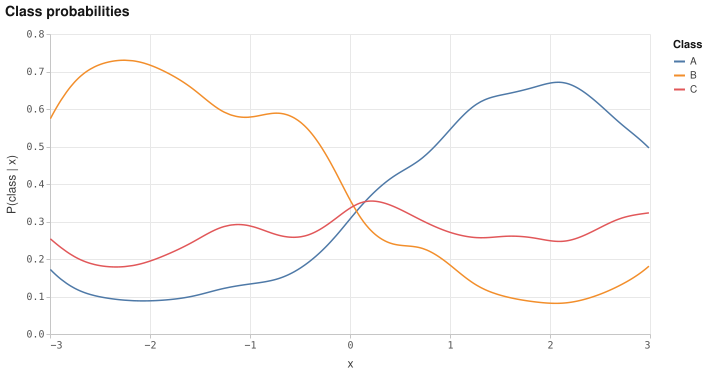

In [3]:
mb.plot.plot_multinomial(m)

You can also access the raw probabilities and draw manually:

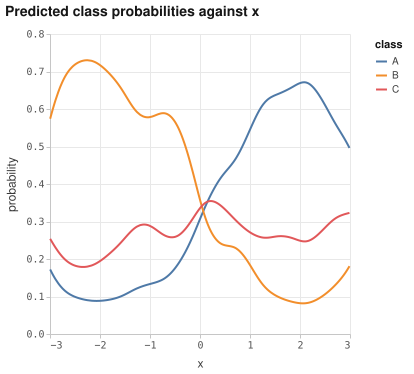

In [4]:
prob = m.predict(type="response")      # columns: A, B, reference(C)
o = np.argsort(x)
import polars as pl
import altair as alt
pdf = pl.DataFrame({"x": x[o]})
for k, lab in enumerate(["A", "B", "C"]):
    pdf = pdf.with_columns(pl.Series(lab, prob[o, k]))
alt.Chart(pdf).transform_fold(["A", "B", "C"], as_=["class", "probability"]).mark_line().encode(
    x="x", y="probability:Q", color="class:N"
).properties(title="Predicted class probabilities against x")

The probability curves cross smoothly with `x`, which a linear multinomial model
could not represent. See [](plotting_serialization.ipynb) for all plotting functions.

## Prediction on new data

In [5]:
nx = np.array([-2.0, 0.0, 2.0])
probs_new = m.predict(newdata={"x": nx}, type="response")
np.round(probs_new, 3)

array([[0.089, 0.717, 0.194],
       [0.307, 0.358, 0.336],
       [0.669, 0.082, 0.249]])

## Example: Fisher's iris data

Fisher's iris data are a three-class benchmark. Fit the model on petal
length and width, then draw the resulting decision regions:

```{note}
`Multinomial` requires `gamboost` (not `glmboost`) for a categorical
string/factor response — `glmboost` extracts the response as a plain
float array and raises a `ValueError` on a string column. Use explicit
`bols()`/`bbs()` terms with `gamboost` for multinomial models.
```

In [6]:
iris = mb.datasets.iris()
iris_data = {c.replace(".", "_"): iris[c].to_numpy() for c in iris.columns if c != "Species"}
iris_data["Species"] = iris["Species"].to_numpy().astype(str)
iris_classes = sorted(set(iris_data["Species"].tolist()))

m_iris = mb.gamboost("Species ~ bols(Petal_Length) + bols(Petal_Width)",
                      data=iris_data, family=mb.Multinomial(),
                      control=mb.boost_control(mstop=300, nu=0.1))
iris_prob = m_iris.predict(type="response")
iris_pred = np.array(iris_classes)[np.argmax(iris_prob, axis=1)]
print(f"training accuracy: {np.mean(iris_pred == iris_data['Species']):.3f}")


training accuracy: 0.947


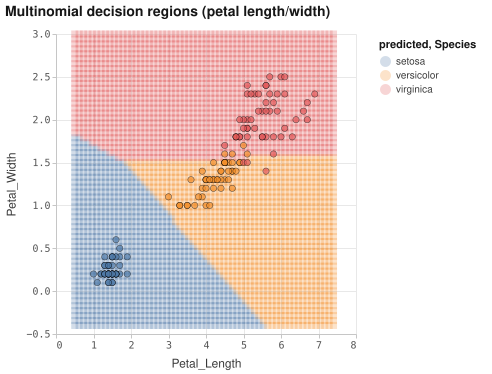

In [7]:
pl_grid = np.linspace(iris_data["Petal_Length"].min() - 0.5,
                       iris_data["Petal_Length"].max() + 0.5, 60)
pw_grid = np.linspace(iris_data["Petal_Width"].min() - 0.5,
                       iris_data["Petal_Width"].max() + 0.5, 60)
PL, PW = np.meshgrid(pl_grid, pw_grid)
grid_prob = m_iris.predict(newdata={"Petal_Length": PL.ravel(), "Petal_Width": PW.ravel()},
                           type="response")
grid_class = np.array(iris_classes)[np.argmax(grid_prob, axis=1)]
grid_pdf = pl.DataFrame({"Petal_Length": PL.ravel(), "Petal_Width": PW.ravel(),
                         "predicted": grid_class})

bg = alt.Chart(grid_pdf).mark_square(size=50, opacity=0.25).encode(
    x="Petal_Length:Q", y="Petal_Width:Q", color="predicted:N")
pts_pdf = pl.DataFrame({"Petal_Length": iris_data["Petal_Length"],
                        "Petal_Width": iris_data["Petal_Width"],
                        "Species": iris_data["Species"]})
pts = alt.Chart(pts_pdf).mark_circle(size=40, stroke="black", strokeWidth=0.5).encode(
    x="Petal_Length:Q", y="Petal_Width:Q", color="Species:N")
(bg + pts).properties(title="Multinomial decision regions (petal length/width)")


*Setosa* separates perfectly on petal size alone; the *versicolor*/*virginica*
boundary is where the handful of training errors live, consistent with the
well-known overlap between those two species on these two measurements.
Iris is small and nearly linearly separable. The Glass dataset (9 predictors,
6–7 classes) would provide a more difficult test of the Kronecker learner and
$q$ truncation in stability selection ([](stability_selection.ipynb));
`mboostrs` does not currently distribute it.

## Multinomial in R

The `Multinomial()` family is available in R:

```r
library(mboostrs)
set.seed(6)
n <- 600
x <- runif(n, -3, 3)
eta <- cbind(sin(x), -0.5 * x)
p <- exp(cbind(eta, 0))
p <- p / rowSums(p)
y <- apply(p, 1, function(pi) sample(c("A", "B", "C"), 1, prob = pi))
data <- data.frame(x, y = factor(y))

m <- gamboost(y ~ bbs(x, df = 4), data = data, family = Multinomial(),
              control = boost_control(300, 0.1))

prob <- predict(m, type = "response")
cat("prob shape:", dim(prob), "\n")
```

```{note}
The Multinomial family is built on a Kronecker-product design (class × covariate);
the details, and the reverse-engineering of R `mboost`'s `%O%` construction, are
in [](../implementation/kronecker_multinomial). Linear (`bols`) and `bbs`
learners are supported; other learners raise a clear error. The `model.cvrisk()` method is not yet supported for Multinomial models;
choose `mstop` with a validation split or a manual external CV loop.
```